# Info 2950 Phase II

### Project: Inflation and Monthly S&P 500 Returns (2017–2026)

**Group:** Jaemin Kwon (jk2975), Mike Zhang (hz727) Neither group member is a native English speaker.


## Research Question

We want to understand how inflation relates to monthly S&P 500 price returns. Higher inflation may coincide with higher interest rates or rising business costs, which could put pressure on stock prices. However, it can also occur when demand and earnings are growing, so we should not assume the relationship is negative.

**Between January 2017 and September 2026, do months with higher year-over-year headline CPI inflation tend to have lower S&P 500 price returns? Does the pattern also appear with core CPI, and how do consumer inflation expectations compare with recent inflation?**

We use headline CPI as the main measure and keep core CPI and expectations as secondary comparisons. We match observations by calendar month. This is a study of associations, not evidence that inflation causes stock returns or a test of a trading strategy.

## Data Collection and Cleaning

### Collection

We combine four series from three underlying producers, all distributed through FRED. All files were downloaded as `.csv` and are stored unmodified in `data/raw/`; every transformation below begins from those files.

**Source 1 — Federal Reserve Economic Data (FRED), Federal Reserve Bank of St. Louis.** We downloaded three series directly from their FRED series pages:

| Series ID | Measures | Frequency | Produced by |
|---|---|---|---|
| `SP500` | S&P 500 closing index level (price only, no dividends) | Daily | S&P Dow Jones Indices LLC |
| `CPIAUCNS` | CPI for All Urban Consumers, All Items, not seasonally adjusted | Monthly | U.S. Bureau of Labor Statistics |
| `CPILFENS` | CPI for All Urban Consumers, All Items Less Food and Energy, not seasonally adjusted | Monthly | U.S. Bureau of Labor Statistics |

**Source 2 — University of Michigan Surveys of Consumers**, distributed through FRED:

| Series ID | Measures | Frequency | Produced by |
|---|---|---|---|
| `MICH` | Median expected price change over the next 12 months | Monthly | University of Michigan Surveys of Consumers |

These are distinct sources rather than one dataset under different names. The S&P 500 series is market transaction data from a private index provider. The two CPI series come from a government price survey. `MICH` is a household opinion survey run by a university. What lets us put them together is the calendar month, and the combination is the point: no single one of these files can tell us how inflation and stock returns move relative to each other.

Two choices in the selection are worth explaining. We use the not-seasonally-adjusted CPI because we compute year-over-year changes, and comparing the same month across years reduces the influence of recurring seasonal patterns. We use the price-only S&P 500 series because that is what FRED publishes; the consequences of leaving out dividends are discussed under Data Limitations.

### Cleaning

The steps below turn four raw files into one analysis-ready table where each row is a calendar month. We save intermediate files along the way so that later phases do not have to rebuild everything from scratch.

#### Step 1 — Import libraries and read the raw files

We import the libraries used throughout, then read all four files without altering them, so that our starting point is exactly what we downloaded.

**Where the data files are.** The cell below reads the four raw `.csv` files from the location named in `DATA`. By default this is our project repository on GitHub, so the notebook runs anywhere with an internet connection, including a fresh Google Colab session, without any files needing to be uploaded first. `pd.read_csv` accepts a web address in place of a file path, so nothing else in the notebook has to change.

To run instead from a copy of the data stored alongside this notebook, comment out the GitHub line and uncomment `DATA = "data/raw"`.

In [1]:
# Libraries for handling and reshaping the data
import pandas as pd
import numpy as np

# Libraries for the plots in the exploratory section
import matplotlib.pyplot as plt
import seaborn as sns

# Regression tool used in HW3 and in lecture
from sklearn.linear_model import LinearRegression

# Display settings so that tables and figures are readable in this notebook
%matplotlib inline
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Where the raw data files live.
# Default: read from our project repository, which works anywhere including Google Colab.
# To read from a local data/raw folder next to this notebook, swap which line is commented.
# DATA = "data/raw"
DATA = "https://raw.githubusercontent.com/jkwon128/INFO2950-Project/main/data/raw"

# Read the four files exactly as downloaded from FRED
sp500_raw = pd.read_csv(f"{DATA}/SP500.csv")        # daily S&P 500 closing level
headline_raw = pd.read_csv(f"{DATA}/CPIAUCNS.csv")  # monthly headline CPI index
core_raw = pd.read_csv(f"{DATA}/CPILFENS.csv")      # monthly core CPI index
mich_raw = pd.read_csv(f"{DATA}/MICH.csv")          # monthly expected inflation, percent

print("All four raw files loaded from:", DATA)

All four raw files loaded from: https://raw.githubusercontent.com/jkwon128/INFO2950-Project/main/data/raw


The four files loaded successfully. Next, we check their size, columns, and missing values.

#### Step 2 — Initial inspection

We check the dimensions, first rows, and missing values of each file before cleaning.

In [2]:
# Check dimensions, first rows, and missing values for each raw file
for name, frame in [("SP500 daily", sp500_raw),
                    ("CPIAUCNS headline CPI monthly", headline_raw),
                    ("CPILFENS core CPI monthly", core_raw),
                    ("MICH expected inflation monthly", mich_raw)]:
    print("=" * 70)
    print(name, "- shape:", frame.shape)
    print(frame.head(3))
    print("Missing values per column:")
    print(frame.isna().sum())

SP500 daily - shape: (2599, 2)
  observation_date    SP500
0       2016-10-14  2132.98
1       2016-10-17  2126.50
2       2016-10-18  2139.60
Missing values per column:
observation_date     0
SP500               96
dtype: int64
CPIAUCNS headline CPI monthly - shape: (141, 2)
  observation_date  CPIAUCNS
0       2015-01-01   233.707
1       2015-02-01   234.722
2       2015-03-01   236.119
Missing values per column:
observation_date    0
CPIAUCNS            1
dtype: int64
CPILFENS core CPI monthly - shape: (141, 2)
  observation_date  CPILFENS
0       2015-01-01   239.248
1       2015-02-01   240.083
2       2015-03-01   241.067
Missing values per column:
observation_date    0
CPILFENS            1
dtype: int64
MICH expected inflation monthly - shape: (119, 2)
  observation_date  MICH
0       2016-10-01   2.4
1       2016-11-01   2.4
2       2016-12-01   2.2
Missing values per column:
observation_date    0
MICH                0
dtype: int64


The stock file contains 2,599 daily rows and 96 missing prices. We remove rows without a price before selecting each month's last available close. Both CPI files contain 141 monthly rows with one missing value; we identify that month below.

The expectations file contains 119 monthly observations and no missing values within its coverage. It ends in August 2026, one month before the other series. We need to convert daily stock prices to monthly returns before merging the files.

#### Step 2b — Finding the missing CPI month

A single missing value is worth tracking down rather than dropping quietly, because which month is missing determines which months we are able to analyze.

In [3]:
# Find the rows of each CPI series that have no published index value
print("Headline CPI months with no value:")
print(headline_raw[headline_raw["CPIAUCNS"].isna()])
print()
print("Core CPI months with no value:")
print(core_raw[core_raw["CPILFENS"].isna()])

Headline CPI months with no value:
    observation_date  CPIAUCNS
129       2025-10-01       NaN

Core CPI months with no value:
    observation_date  CPILFENS
129       2025-10-01       NaN


Both CPI series are missing **October 2025**. BLS describes the interruption in its [2025 government shutdown FAQ](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm). We leave the values missing and record the excluded month.

This gap also prevents a year-over-year comparison for October 2026, because its base month would be October 2025. Our analysis ends in September 2026, so that additional gap does not affect this sample.

#### Step 3 — Standardize names, dates and calendar columns

We rename the columns, convert dates to datetime values, and extract the year and month. We also create **`month_index = Year * 12 + Month`**. With this key, the previous month is one lower and the same month last year is twelve lower, including across year boundaries.

The value columns are already numeric, and blank entries were read as missing values.

In [4]:
# Rename columns so that all four frames follow the same pattern
sp500 = sp500_raw.rename(columns={"observation_date": "date", "SP500": "sp500_close"})
headline = headline_raw.rename(columns={"observation_date": "date", "CPIAUCNS": "headline_cpi"})
core = core_raw.rename(columns={"observation_date": "date", "CPILFENS": "core_cpi"})
mich = mich_raw.rename(columns={"observation_date": "date", "MICH": "expected_inflation_pct"})

# Convert dates, then add Year, Month and a running month counter to each frame
for frame in (sp500, headline, core, mich):
    frame["date"] = pd.to_datetime(frame["date"])
    frame["Year"] = frame["date"].dt.year
    frame["Month"] = frame["date"].dt.month
    # month_index counts months continuously, so one month back is always one lower
    frame["month_index"] = frame["Year"] * 12 + frame["Month"]

# Confirm the result
print("S&P 500 data types:")
print(sp500.dtypes)
print()
print(sp500.head(3))
print()
print(headline.head(3))

S&P 500 data types:
date           datetime64[ns]
sp500_close           float64
Year                    int32
Month                   int32
month_index             int32
dtype: object

        date  sp500_close  Year  Month  month_index
0 2016-10-14      2132.98  2016     10        24202
1 2016-10-17      2126.50  2016     10        24202
2 2016-10-18      2139.60  2016     10        24202

        date  headline_cpi  Year  Month  month_index
0 2015-01-01       233.707  2015      1        24181
1 2015-02-01       234.722  2015      2        24182
2 2015-03-01       236.119  2015      3        24183


The date columns now use datetime values, and each table has a year, month, and shared month key. The values are numeric.

#### Step 4 — Reduce daily prices to monthly returns

We use the last available trading-day close in each month. Grouping by month gives us the latest date, which we merge back onto the daily table to retrieve its price.

We then match each close to the previous month's close and calculate **`100 × (current close − previous close) / previous close`**. This measures the change between month-end prices rather than a change in monthly average prices.

In [5]:
# Drop the 96 market-holiday rows that have no closing price
sp500_trading = sp500.dropna(subset=["sp500_close"])
print("Daily rows before dropping holidays:", len(sp500))
print("Daily rows after dropping holidays:", len(sp500_trading))

# Find the last trading date within each calendar month
month_ends = (sp500_trading
              .groupby(["Year", "Month", "month_index"], as_index=False)["date"]
              .max()
              .rename(columns={"date": "last_trading_date"}))

# Merge that date back onto the daily data to pick up the closing price on that day
monthly_price = month_ends.merge(
    sp500_trading[["date", "sp500_close"]],
    left_on="last_trading_date", right_on="date", how="left").drop(columns="date")

# Build a copy labelled one month later, so each month lines up with the previous month
previous_month = monthly_price[["month_index", "sp500_close"]].copy()
previous_month["month_index"] = previous_month["month_index"] + 1
previous_month = previous_month.rename(columns={"sp500_close": "previous_close"})

# Monthly price return (%) = percent change from the previous month-end close
monthly_price = monthly_price.merge(previous_month, on="month_index", how="left")
monthly_price["sp500_return_pct"] = ((monthly_price["sp500_close"] - monthly_price["previous_close"])
                                     / monthly_price["previous_close"]) * 100

monthly_price = monthly_price.sort_values("month_index").reset_index(drop=True)
print("\nMonthly price observations:", len(monthly_price))
print(monthly_price.head(5))

Daily rows before dropping holidays: 2599
Daily rows after dropping holidays: 2503

Monthly price observations: 120
   Year  Month  month_index last_trading_date  sp500_close  previous_close  sp500_return_pct
0  2016     10        24202        2016-10-31      2126.15             NaN               NaN
1  2016     11        24203        2016-11-30      2198.81         2126.15          3.417445
2  2016     12        24204        2016-12-30      2238.83         2198.81          1.820075
3  2017      1        24205        2017-01-31      2278.87         2238.83          1.788434
4  2017      2        24206        2017-02-28      2363.64         2278.87          3.719826


After removing 96 missing-price rows, we obtain 120 month-end observations. October 2016 has no return because the preceding month-end price is unavailable.

The raw data start midway through October, but include its final trading-day close, so a November return can still be calculated. We start our analysis in January 2017 to use a calendar-year boundary within the available stock-price history.

#### Step 5 — Compute year-over-year inflation

Inflation is not the level of the CPI but its rate of change. We use the year-over-year change, which is the percent change in the index from the same month one year earlier. A twelve-month change is less sensitive to short-term monthly movements than a month-over-month change, and it is the form in which inflation is normally reported.

**Year-over-year inflation (%) = (Current CPI - CPI 12 months ago) / (CPI 12 months ago) × 100**

We build this with the same approach used for returns in Step 4: make a copy of the CPI table with **`month_index`** increased by twelve and merge it back, so that each month sits alongside its own base month. Doing it this way keeps the alignment visible, and a month with no data produces a missing rate rather than being silently skipped.

In [6]:
# Build a year-over-year percent change for one CPI series
def add_year_over_year(frame, level_column, new_column):
    """Return a monthly table with a year-over-year percent change column.

    frame        : a monthly CPI frame with month_index, Year, Month and a level column
    level_column : name of the CPI level column
    new_column   : name to give the new percent change column
    """
    result = frame[["month_index", "Year", "Month", level_column]].copy()

    # Copy the same data labelled twelve months later, so each month meets its base year
    base = result[["month_index", level_column]].copy()
    base["month_index"] = base["month_index"] + 12
    base = base.rename(columns={level_column: "base_value"})

    result = result.merge(base, on="month_index", how="left")
    result[new_column] = (result[level_column] - result["base_value"]) / result["base_value"] * 100
    return result.drop(columns="base_value")

# Year-over-year inflation for the headline and core CPI series
headline_yoy = add_year_over_year(headline, "headline_cpi", "headline_yoy_pct")
core_yoy = add_year_over_year(core, "core_cpi", "core_yoy_pct")

# The expectations series is already expressed as a percent, so it only needs its key columns
expected_monthly = mich[["month_index", "expected_inflation_pct"]].copy()

print("Headline inflation, first months with a computable rate:")
print(headline_yoy.dropna(subset=["headline_yoy_pct"]).head(3))
print("\nMonths with no computable headline inflation rate:",
      headline_yoy["headline_yoy_pct"].isna().sum())

Headline inflation, first months with a computable rate:
    month_index  Year  Month  headline_cpi  headline_yoy_pct
12        24193  2016      1       236.916          1.373087
13        24194  2016      2       237.111          1.017800
14        24195  2016      3       238.132          0.852536

Months with no computable headline inflation rate: 13


The first twelve CPI observations supply the base values, so year-over-year rates begin in January 2016. Each CPI table has 13 missing rates: the twelve months of 2015 and October 2025. The merge keeps missing months from being mistaken for a different base month.

#### Step 6 — Check each monthly series before merging

Two problems would quietly corrupt a merge: duplicate months, which would multiply rows, and unexpected date coverage. We check for both, then save the cleaned monthly pieces.

In [7]:
# Check each cleaned monthly series for duplicate months and report its coverage
for name, frame in [("S&P 500 monthly", monthly_price),
                    ("Headline inflation", headline_yoy),
                    ("Core inflation", core_yoy),
                    ("Expected inflation", expected_monthly)]:
    duplicates = frame["month_index"].duplicated().sum()
    print(f"{name:22} rows={len(frame):4d}  duplicate months={duplicates}  "
          f"month_index {frame['month_index'].min()} to {frame['month_index'].max()}")

# Save the cleaned monthly pieces so that later phases need not rebuild them
monthly_price.to_csv("monthly_sp500_cleaned.csv", index=False)
headline_yoy.to_csv("monthly_headline_inflation_cleaned.csv", index=False)
core_yoy.to_csv("monthly_core_inflation_cleaned.csv", index=False)
expected_monthly.to_csv("monthly_expected_inflation_cleaned.csv", index=False)
print("\nFour intermediate cleaned files saved.")

S&P 500 monthly        rows= 120  duplicate months=0  month_index 24202 to 24321
Headline inflation     rows= 141  duplicate months=0  month_index 24181 to 24321
Core inflation         rows= 141  duplicate months=0  month_index 24181 to 24321
Expected inflation     rows= 119  duplicate months=0  month_index 24202 to 24320

Four intermediate cleaned files saved.


There are no duplicate month keys. The stock and CPI tables end in September 2026, while expectations end in August 2026. We save these intermediate tables before combining them.

#### Step 7 — Merge into the analysis-ready dataset

We merge the four tables on **`month_index`** and restrict them to January 2017–September 2026. January 2017 is our chosen calendar-year starting point; September 2026 is the last month available in both the stock and CPI snapshots.

We require a stock return and headline inflation rate for each retained month. Missing secondary measurements do not remove an otherwise usable month. We save the excluded rows separately.

In [8]:
# Merge the four monthly series on the shared month counter
merged = (monthly_price[["month_index", "Year", "Month", "last_trading_date",
                         "sp500_close", "sp500_return_pct"]]
          .merge(headline_yoy[["month_index", "headline_cpi", "headline_yoy_pct"]],
                 on="month_index", how="left")
          .merge(core_yoy[["month_index", "core_cpi", "core_yoy_pct"]],
                 on="month_index", how="left")
          .merge(expected_monthly, on="month_index", how="left")
          .sort_values("month_index")
          .reset_index(drop=True))

print("Rows after merging all four series:", len(merged))
print("Missing values per column:")
print(merged.isna().sum())

# Restrict to the analysis window, using the month counter for January 2017 and September 2026
start_index = 2017 * 12 + 1
end_index = 2026 * 12 + 9
window = merged[(merged["month_index"] >= start_index) &
                (merged["month_index"] <= end_index)]
print("\nRows inside the January 2017 to September 2026 window:", len(window))

# A month can be analyzed only if it has both a return and a headline inflation rate
analysis_df = window.dropna(subset=["sp500_return_pct", "headline_yoy_pct"]).reset_index(drop=True)
excluded = window[window["sp500_return_pct"].isna() | window["headline_yoy_pct"].isna()]

print("Months in the final analysis dataset:", len(analysis_df))
print("Months excluded from the window:", len(excluded))
print("\nExcluded month(s):")
print(excluded[["Year", "Month", "sp500_return_pct", "headline_yoy_pct"]])

# Save the merged table, the final dataset and the record of what was excluded
merged.to_csv("merged_all_months.csv", index=False)
analysis_df.to_csv("analysis_dataset.csv", index=False)
excluded.to_csv("excluded_months.csv", index=False)
print("\nFinal analysis dataset and exclusion log saved.")
print(analysis_df.head(5))

Rows after merging all four series: 120
Missing values per column:
month_index               0
Year                      0
Month                     0
last_trading_date         0
sp500_close               0
sp500_return_pct          1
headline_cpi              1
headline_yoy_pct          1
core_cpi                  1
core_yoy_pct              1
expected_inflation_pct    1
dtype: int64

Rows inside the January 2017 to September 2026 window: 117
Months in the final analysis dataset: 116
Months excluded from the window: 1

Excluded month(s):
     Year  Month  sp500_return_pct  headline_yoy_pct
108  2025     10          2.268684               NaN

Final analysis dataset and exclusion log saved.
   month_index  Year  Month last_trading_date  sp500_close  sp500_return_pct  headline_cpi  \
0        24205  2017      1        2017-01-31      2278.87          1.788434       242.839   
1        24206  2017      2        2017-02-28      2363.64          3.719826       243.603   
2        24207  20

The window contains 117 months. Excluding October 2025 because of missing CPI leaves **116 months**. The excluded row is saved in **`excluded_months.csv`**.

September 2026 has no expectations value, but we retain it because returns and CPI are available. Comparisons involving expectations therefore use **115 months**.

## Data Description

*This section follows the format of Gebru et al. (2021), "Datasheets for Datasets." The full reference appears under Sources and Acknowledgements.*

### What are the observations (rows) and the attributes (columns)?

Our analysis-ready file, **`analysis_dataset.csv`**, has **116 monthly observations** from January 2017 to September 2026, excluding October 2025 because CPI data are missing. Each row represents one month.

There are **11 columns**:

| Column | Meaning | Units |
|---|---|---|
| `month_index` | Running month counter, `Year * 12 + Month` | Count |
| `Year` | Calendar year | Year |
| `Month` | Calendar month | 1–12 |
| `last_trading_date` | Final trading day of that month | Date |
| `sp500_close` | S&P 500 closing level on that day | Index points |
| `sp500_return_pct` | Outcome variable: price return from the previous month-end close | Percent |
| `headline_cpi` | Headline CPI-U index level, all items | Index, 1982–84 = 100 |
| `headline_yoy_pct` | Main explanatory variable: year-over-year change in headline CPI | Percent |
| `core_cpi` | Core CPI-U index level, less food and energy | Index, 1982–84 = 100 |
| `core_yoy_pct` | Year-over-year change in core CPI | Percent |
| `expected_inflation_pct` | Median expected price change over the next 12 months | Percent |

The four main analysis variables are expressed in percent; a one-unit difference means one percentage point.

### Why was this dataset created?

We assembled it for our INFO 2950 project to study whether higher inflation coincides with lower monthly S&P 500 price returns. Combining separate CPI, stock-market and consumer-expectation series lets us compare them on a common monthly timeline.

### How did you create this dataset? What tools, procedures and data sources did you use?

We downloaded four publicly available FRED CSV series: `SP500`, `CPIAUCNS`, `CPILFENS` and `MICH`. We used Python and `pandas` to clean and merge them. Plots use `matplotlib` and `seaborn`, and supplementary regressions use `scikit-learn`. The seven cleaning steps and code appear above; we did not collect any new observations ourselves.

### Who funded the creation of the dataset?

We received no external funding for this merged dataset. The underlying series were produced by S&P Dow Jones Indices (S&P 500), the U.S. Bureau of Labor Statistics (CPI) and the University of Michigan Surveys of Consumers (inflation expectations), and distributed through FRED.

### What processes might have influenced what data was observed and recorded, and what was not?

- **CPI:** CPI-U measures prices for urban consumers (about 93% of the U.S. population), not all households. Its values depend on BLS choices about goods, geographic coverage and price adjustments. October 2025 CPI values are unavailable because collection was interrupted during the government shutdown.
- **S&P 500:** The price index excludes dividends and covers large publicly traded U.S. companies, not smaller or private firms. Monthly aggregation also hides movements within each month.
- **Inflation expectations:** `MICH` is a survey measure of what consumers expect over the next twelve months, not an observed future inflation rate. Responses are self-reported and published as a median.

### What preprocessing was done, and how did the data come to be in the form that you are using?

As documented in the cleaning section, we checked missing values, standardized dates and column names, and aligned the four series by `month_index`. We removed **96 daily rows without S&P 500 prices**, calculated returns from consecutive month-end closes, and computed year-over-year headline and core CPI inflation. We also checked for duplicate months and saved intermediate cleaned files.

We excluded October 2025 from the final dataset because CPI data are missing and logged the exclusion. The September 2026 inflation-expectations value is also missing, so analyses using `MICH` have **115 rather than 116 observations**. **No missing values were imputed.**

### If people are involved, were they aware of the data collection, and what purpose did they expect the data to be used for?

CPI and consumer expectations draw partly on survey responses. We use only published aggregate data, with no individual identifiers. We did not contact respondents or independently verify the original consent procedures; our use is for classroom analysis.

### Where can your raw source data be found?

- S&P 500 index level (`SP500`): https://fred.stlouisfed.org/series/SP500
- Headline CPI, all items, not seasonally adjusted (`CPIAUCNS`): https://fred.stlouisfed.org/series/CPIAUCNS
- Core CPI, less food and energy, not seasonally adjusted (`CPILFENS`): https://fred.stlouisfed.org/series/CPILFENS
- University of Michigan inflation expectations (`MICH`): https://fred.stlouisfed.org/series/MICH
- Our raw downloads, cleaning code and cleaned dataset: https://github.com/jkwon128/INFO2950-Project


## Data Limitations

- **Price returns exclude dividends.** These returns do not measure the full return from holding stocks with reinvested dividends. We have not estimated that difference for this sample.
- **One CPI month is missing.** October 2025 was unavailable because of the shutdown. We exclude it without imputation. This is a gap caused by a collection interruption, not random sampling.
- **The observations are related over time.** Adjacent year-over-year inflation rates share eleven months of price changes. Regression uncertainty depends on the behavior of the model's residuals; ordinary p-values may be unreliable if those assumptions fail.
- **The period is limited.** The sample includes the 2020 market crash and rebound and the later inflation surge. Results from these 116 months may not apply to other periods.
- **The timing does not support prediction.** A month's CPI is generally released the following month. Matching it to the same calendar month's return does not show what investors could have predicted at the time.
- **Other factors affect returns.** Earnings, interest rates, employment, and other events may affect both inflation and stock prices. Our simple comparisons do not separate those influences.
- **Each measure covers only part of the economy.** CPI-U represents urban consumers, core CPI excludes food and energy, and the S&P 500 represents large U.S. companies. Consumer expectations also need not match investor beliefs.

### How these limitations could affect people

A reader could mistake a negative association for a reason to sell stocks whenever inflation rises. Our analysis does not test whether that strategy works. We will describe the results as historical associations and explain the missing data, limited coverage, and uncertainty.

## Exploratory Data Analysis

We use summary statistics and plots to describe the variables and their relationships. We report correlations but do not fit either planned return regression here. The two fitted models in EDA 8 and 9 compare inflation measures with one another.

The correlations and summary statistics already reveal information about the planned same-month headline return model. Part 2 explains this overlap and proposes a second analysis using the previous calendar month’s inflation, which is not estimated in the EDA.

### EDA 1 — Summary statistics

We begin with typical values and spread for the four analysis variables.

In [9]:
# Summary statistics for the four analysis variables
analysis_vars = ["sp500_return_pct", "headline_yoy_pct", "core_yoy_pct", "expected_inflation_pct"]
summary = analysis_df[analysis_vars].describe().round(3)
print("Sample:", len(analysis_df), "months, from",
      f"{analysis_df['Year'].iloc[0]}-{analysis_df['Month'].iloc[0]:02d}", "to",
      f"{analysis_df['Year'].iloc[-1]}-{analysis_df['Month'].iloc[-1]:02d}")
print(summary)

# Skewness indicates whether each distribution is symmetric
print("\nSkewness:")
print(analysis_df[analysis_vars].skew().round(3))

# Save the summary table for reuse in the final report
summary.to_csv("summary_statistics.csv")

Sample: 116 months, from 2017-01 to 2026-09
       sp500_return_pct  headline_yoy_pct  core_yoy_pct  expected_inflation_pct
count           116.000           116.000       116.000                 115.000
mean              1.146             3.351         3.150                   3.528
std               4.491             2.040         1.468                   1.025
min             -12.512             0.118         1.187                   2.100
25%              -1.008             2.066         2.111                   2.700
50%               1.790             2.720         2.614                   3.100
75%               3.630             3.709         4.002                   4.500
max              12.684             9.060         6.631                   6.600

Skewness:
sp500_return_pct         -0.427
headline_yoy_pct          1.300
core_yoy_pct              0.910
expected_inflation_pct    0.772
dtype: float64


Monthly returns average **1.15%**, with a median of **1.79%** and a standard deviation of **4.49 percentage points**. They range from **−12.51% to +12.68%**. The negative skewness of −0.43 indicates some asymmetry toward losses.

Headline inflation averages **3.35%**, with a median of **2.72%** and a range of **0.12% to 9.06%**. Its positive skewness reflects the smaller group of high-inflation months.

Core inflation averages **3.15%** and varies less than headline inflation: its standard deviation is **1.47**, compared with **2.04** percentage points. Expectations average **3.53%**, with a standard deviation of **1.03** and a sample minimum of **2.1%**. Expectations have 115 observations; the other variables have 116.

Next, we check whether movements in these measures line up with returns.

### EDA 2 — Correlations between the variables

Next we look at how the four variables move together. These are descriptive correlation coefficients rather than fitted models or tests.

In [10]:
# Correlation matrix among the four analysis variables
correlations = analysis_df[analysis_vars].corr().round(3)
print("Correlations, January 2017 to September 2026 (n = 116):")
print(correlations)

Correlations, January 2017 to September 2026 (n = 116):
                        sp500_return_pct  headline_yoy_pct  core_yoy_pct  expected_inflation_pct
sp500_return_pct                   1.000            -0.159        -0.122                  -0.035
headline_yoy_pct                  -0.159             1.000         0.920                   0.701
core_yoy_pct                      -0.122             0.920         1.000                   0.664
expected_inflation_pct            -0.035             0.701         0.664                   1.000


Returns have weak negative correlations with headline inflation (**−0.159**), core inflation (**−0.122**), and expectations (**−0.035**). These are descriptive associations, not significance tests. For a simple regression with an intercept, the squared headline correlation corresponds to about **2.5%** of return variation explained in this sample.

Headline and core inflation correlate **0.920**, so the two contemporaneous measures are closely related. Expectations correlate **0.701** with headline and **0.664** with core. Correlations involving expectations use 115 observations; the others use 116.

### EDA 3 — The three inflation measures over time

Plotting inflation over time shows which episodes drive the variation in our main explanatory variable.

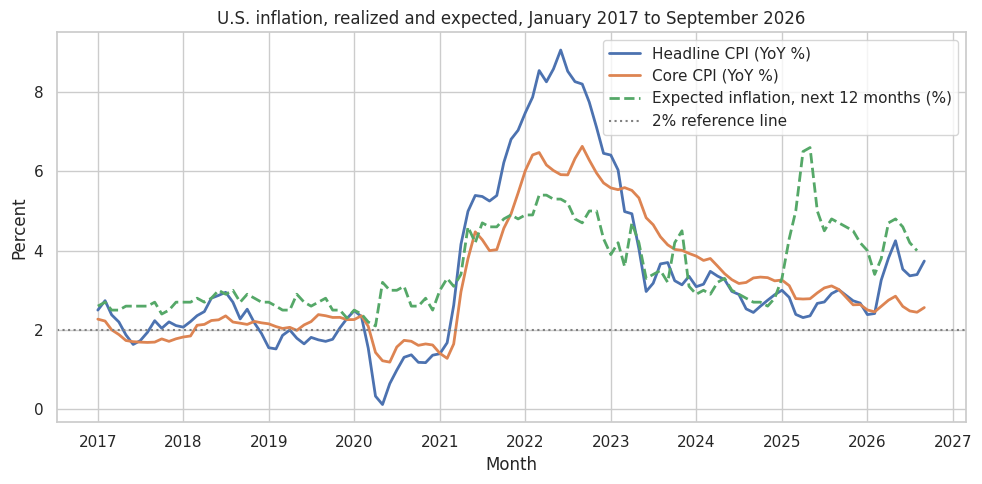

In [11]:
# Build a monthly date column so the figures can use a proper time axis
plot_df = analysis_df.copy()
plot_df["month_date"] = pd.to_datetime(dict(year=plot_df["Year"], month=plot_df["Month"], day=1))

# Plot the three inflation measures together for direct comparison
plt.figure(figsize=(10, 5))
plt.plot(plot_df["month_date"], plot_df["headline_yoy_pct"], label="Headline CPI (YoY %)", linewidth=2)
plt.plot(plot_df["month_date"], plot_df["core_yoy_pct"], label="Core CPI (YoY %)", linewidth=2)
plt.plot(plot_df["month_date"], plot_df["expected_inflation_pct"],
         label="Expected inflation, next 12 months (%)", linewidth=2, linestyle="--")
plt.axhline(2, color="grey", linestyle=":", label="2% reference line")
plt.xlabel("Month")
plt.ylabel("Percent")
plt.title("U.S. inflation, realized and expected, January 2017 to September 2026")
plt.legend()
plt.tight_layout()
plt.show()

Headline inflation falls to **0.12% in May 2020**, then rises to **9.06% in June 2022** before declining. Core follows a similar pattern but has a lower peak.

Expectations do not track recent inflation exactly. They have less variation in this sample and remain above 2.1%. The comparison also involves different horizons: expectations concern the next twelve months, while CPI inflation describes the previous twelve.

### EDA 4 — Monthly returns over time

The same view of our outcome variable shows where the extreme months fall.

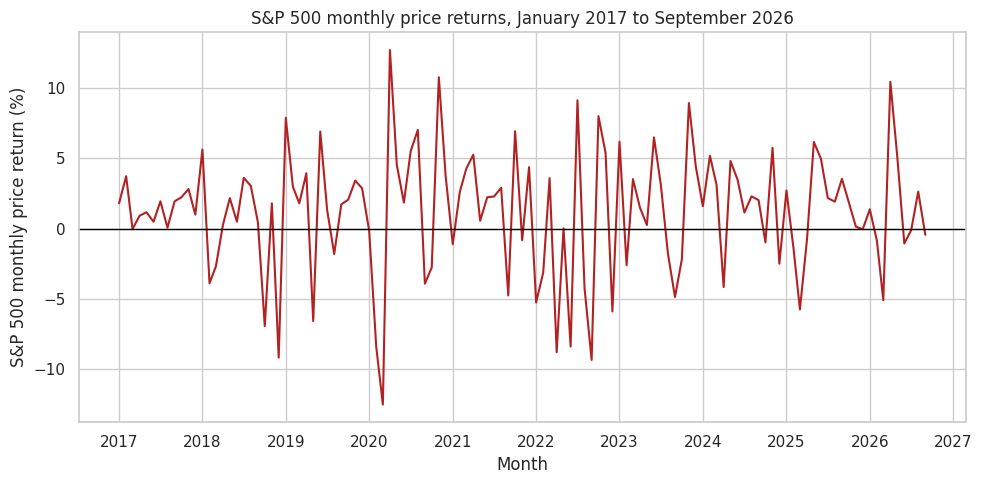

Three worst months:
 Year  Month  sp500_return_pct  headline_yoy_pct
 2020      3        -12.511932          1.539327
 2022      9         -9.339570          8.201670
 2018     12         -9.177696          1.910159

Three best months:
 Year  Month  sp500_return_pct  headline_yoy_pct
 2020      4         12.684410          0.329097
 2020     11         10.754566          1.174536
 2026      4         10.423343          3.810845


In [12]:
# Plot monthly returns over time with a zero reference line
plt.figure(figsize=(10, 5))
plt.plot(plot_df["month_date"], plot_df["sp500_return_pct"], color="firebrick", linewidth=1.5)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Month")
plt.ylabel("S&P 500 monthly price return (%)")
plt.title("S&P 500 monthly price returns, January 2017 to September 2026")
plt.tight_layout()
plt.show()

# Identify the most extreme months so that they can be discussed directly
print("Three worst months:")
print(analysis_df.nsmallest(3, "sp500_return_pct")[
    ["Year", "Month", "sp500_return_pct", "headline_yoy_pct"]].to_string(index=False))
print("\nThree best months:")
print(analysis_df.nlargest(3, "sp500_return_pct")[
    ["Year", "Month", "sp500_return_pct", "headline_yoy_pct"]].to_string(index=False))

The lowest return is **−12.51% in March 2020**, followed by the highest, **+12.68% in April 2020**. Headline inflation in those months was **1.54%** and **0.33%**, respectively, both below the sample mean of 3.35%. The minimum inflation rate was **0.12% in May 2020**.

September 2022 combines a large loss (**−9.34%**) with high inflation (**8.20%**). The different settings for these extreme returns show why inflation alone may explain little of their variation. We retain the observations and will consider their influence when interpreting the later models.

### EDA 5 — Distributions of the two main variables

Histograms let us see the shapes implied by the summary statistics.

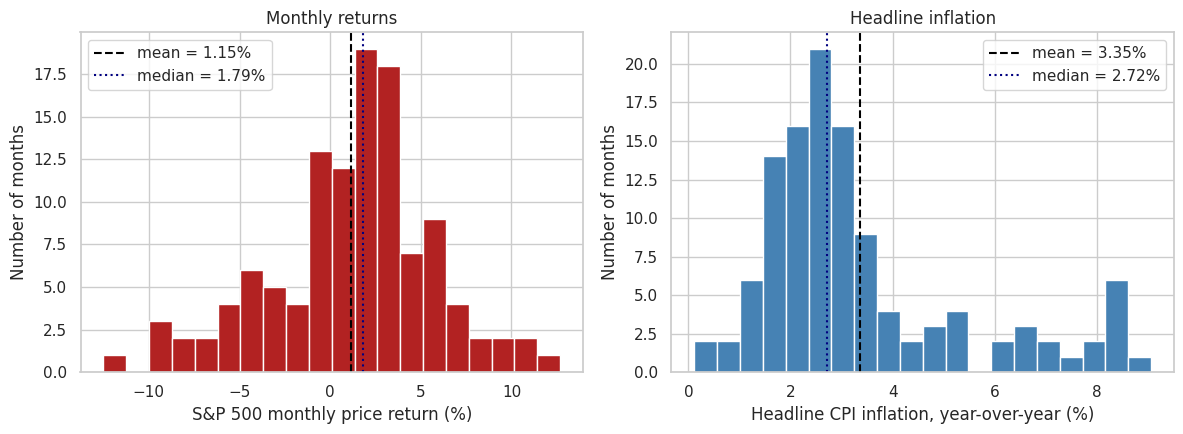

In [13]:
# Two histograms side by side: the outcome and the main explanatory variable
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(analysis_df["sp500_return_pct"], bins=20, color="firebrick", edgecolor="white")
axes[0].axvline(analysis_df["sp500_return_pct"].mean(), color="black", linestyle="--",
                label=f"mean = {analysis_df['sp500_return_pct'].mean():.2f}%")
axes[0].axvline(analysis_df["sp500_return_pct"].median(), color="navy", linestyle=":",
                label=f"median = {analysis_df['sp500_return_pct'].median():.2f}%")
axes[0].set_xlabel("S&P 500 monthly price return (%)")
axes[0].set_ylabel("Number of months")
axes[0].set_title("Monthly returns")
axes[0].legend()

axes[1].hist(analysis_df["headline_yoy_pct"], bins=20, color="steelblue", edgecolor="white")
axes[1].axvline(analysis_df["headline_yoy_pct"].mean(), color="black", linestyle="--",
                label=f"mean = {analysis_df['headline_yoy_pct'].mean():.2f}%")
axes[1].axvline(analysis_df["headline_yoy_pct"].median(), color="navy", linestyle=":",
                label=f"median = {analysis_df['headline_yoy_pct'].median():.2f}%")
axes[1].set_xlabel("Headline CPI inflation, year-over-year (%)")
axes[1].set_ylabel("Number of months")
axes[1].set_title("Headline inflation")
axes[1].legend()

plt.tight_layout()
plt.show()

Returns are concentrated around modest gains, with some large losses and gains. Their mean falls below their median, consistent with the negative skewness in the summary table.

Headline inflation has a longer right tail. Most observations are at lower inflation rates, with fewer months near the high end. Those high values may influence a fitted slope, so we also inspect the scatterplots.

### EDA 6 — Headline inflation against returns

This is the central pair of variables for our research question. As explained above, the scatter appears without a fitted line, because fitting that line is our first preregistered analysis.

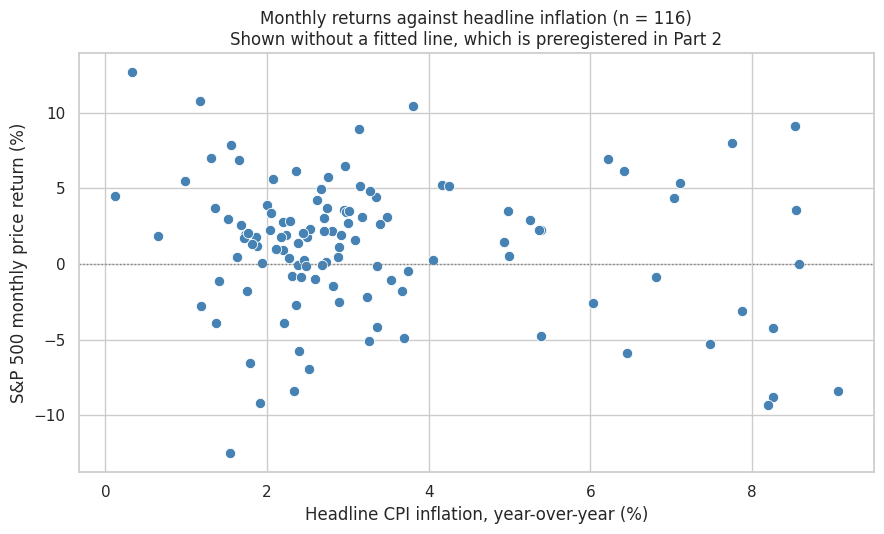

Returns by inflation regime, descriptive only, no test performed:
                   count   mean  median    std
inflation_regime                              
high (above 3%)       46  0.966   1.905  4.889
low (3% or below)     70  1.264   1.790  4.242


In [14]:
# Scatterplot of the central relationship, deliberately without a fitted line
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=analysis_df, x="headline_yoy_pct", y="sp500_return_pct", s=55,
                color="steelblue", edgecolor="white")
plt.axhline(0, color="grey", linewidth=1, linestyle=":")
plt.xlabel("Headline CPI inflation, year-over-year (%)")
plt.ylabel("S&P 500 monthly price return (%)")
plt.title("Monthly returns against headline inflation (n = 116)\n"
          "Shown without a fitted line, which is preregistered in Part 2")
plt.tight_layout()
plt.show()

# Descriptive comparison of months above and below 3% inflation
analysis_df["inflation_regime"] = np.where(analysis_df["headline_yoy_pct"] > 3,
                                           "high (above 3%)", "low (3% or below)")
print("Returns by inflation regime, descriptive only, no test performed:")
print(analysis_df.groupby("inflation_regime")["sp500_return_pct"]
      .agg(["count", "mean", "median", "std"]).round(3))

The scatterplot shows a wide range of returns at similar inflation levels, with gains and losses occurring even at high inflation.

Months above 3% inflation average **0.97%** returns, compared with **1.26%** for months at or below 3%. The medians go the other way: **1.91%** versus **1.79%**. This suggests the comparison depends on which summary we use; it does not establish a consistent difference between the groups. The 3% cutoff is an exploratory choice, and no significance test is performed.

### EDA 7 — Core inflation against returns

The same view using core inflation as a secondary exploratory comparison; no return regression is fitted here.

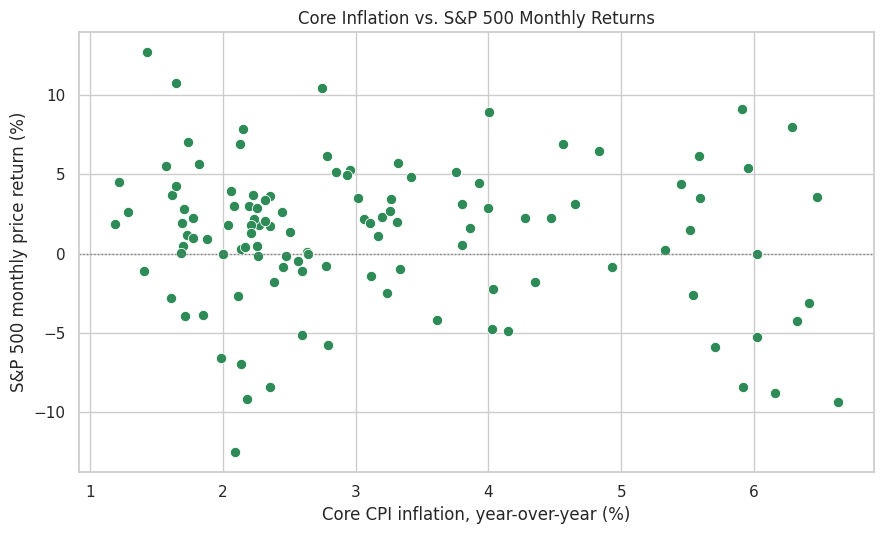

In [15]:
# Scatterplot for the core inflation relationship, also without a fitted line
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=analysis_df, x="core_yoy_pct", y="sp500_return_pct", s=55,
                color="seagreen", edgecolor="white")
plt.axhline(0, color="grey", linewidth=1, linestyle=":")
plt.xlabel("Core CPI inflation, year-over-year (%)")
plt.ylabel("S&P 500 monthly price return (%)")
plt.title("Monthly returns against core inflation (n = 116)")
plt.tight_layout()
plt.show()

Core inflation also shows a wide spread of returns at similar inflation rates. Its range is narrower than headline inflation's, but its correlation with returns is slightly weaker.

A regression slope depends on both correlation and the variables' standard deviations. A larger slope would therefore not, by itself, mean a stronger relationship. We will report R² alongside slopes in the planned return models.

### EDA 8 — How closely do headline and core inflation track each other?

We fit core inflation as a function of headline inflation to describe how closely the two measures move together. This model has core inflation as its outcome, rather than stock returns.

In [16]:
# Regress core inflation on headline inflation using the method practiced in HW3.
# Note: this is NOT a preregistered analysis; the outcome is core inflation, not returns.
reg_df = analysis_df.dropna(subset=["headline_yoy_pct", "core_yoy_pct"])
x_measures = reg_df[["headline_yoy_pct"]]   # predictor must be two-dimensional
y_measures = reg_df["core_yoy_pct"]

model_measures = LinearRegression()
model_measures.fit(x_measures, y_measures)

slope_measures = model_measures.coef_[0]
intercept_measures = model_measures.intercept_
r2_measures = model_measures.score(x_measures, y_measures)

print("Regression of core inflation on headline inflation")
print("Observations:", len(reg_df))
print("Slope:", round(slope_measures, 4))
print("Intercept:", round(intercept_measures, 4))
print("R-squared:", round(r2_measures, 4))

Regression of core inflation on headline inflation
Observations: 116
Slope: 0.6617
Intercept: 0.9325
R-squared: 0.8456


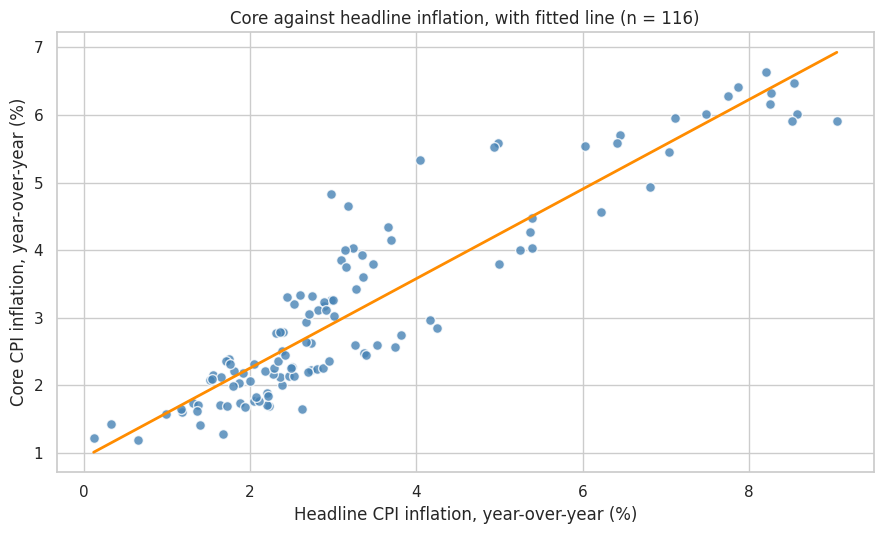

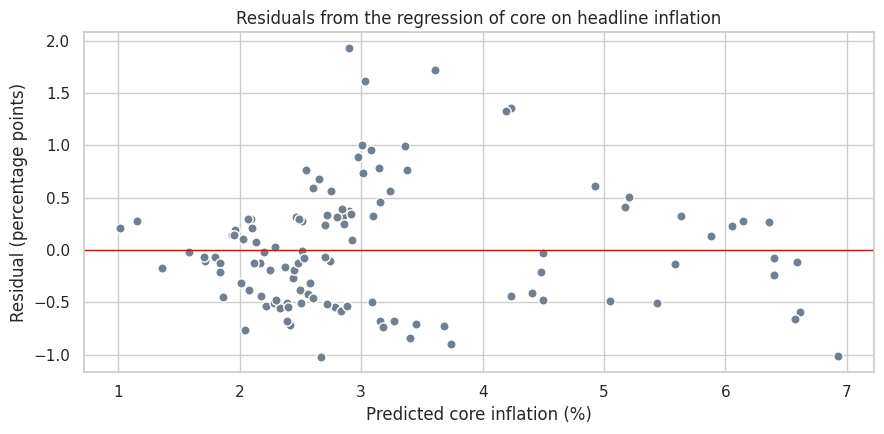

In [17]:
# Plot the fitted relationship between the two inflation measures
plt.figure(figsize=(9, 5.5))
sns.regplot(data=reg_df, x="headline_yoy_pct", y="core_yoy_pct",
            scatter_kws={"s": 50, "color": "steelblue", "edgecolor": "white"},
            line_kws={"color": "darkorange", "linewidth": 2}, ci=None)
plt.xlabel("Headline CPI inflation, year-over-year (%)")
plt.ylabel("Core CPI inflation, year-over-year (%)")
plt.title("Core against headline inflation, with fitted line (n = 116)")
plt.tight_layout()
plt.show()

# Residual plot to check whether a straight line describes the relationship adequately
predicted_core = model_measures.predict(x_measures)
residuals = y_measures - predicted_core

plt.figure(figsize=(9, 4.5))
plt.scatter(predicted_core, residuals, s=45, color="slategrey", edgecolor="white")
plt.axhline(0, color="red", linewidth=1)
plt.xlabel("Predicted core inflation (%)")
plt.ylabel("Residual (percentage points)")
plt.title("Residuals from the regression of core on headline inflation")
plt.tight_layout()
plt.show()

Residuals against predicted values help us inspect the shape and spread of the errors. To examine their pattern over time, we also plot them in date order.

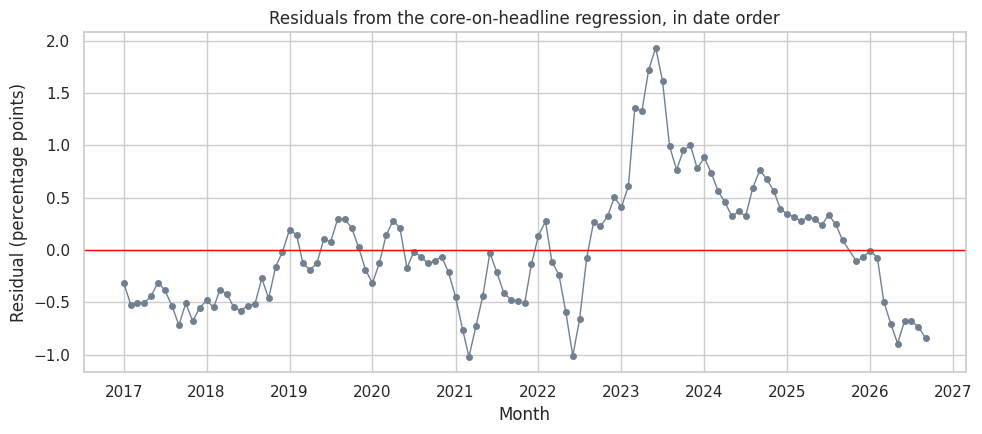

In [18]:
# Plot the same residuals in date order, which is what shows whether errors run in streaks
residual_dates = pd.to_datetime(dict(year=reg_df["Year"], month=reg_df["Month"], day=1))

plt.figure(figsize=(10, 4.5))
plt.plot(residual_dates, residuals, marker="o", linewidth=1, markersize=4, color="slategrey")
plt.axhline(0, color="red", linewidth=1)
plt.xlabel("Month")
plt.ylabel("Residual (percentage points)")
plt.title("Residuals from the core-on-headline regression, in date order")
plt.tight_layout()
plt.show()

The time plot shows long stretches of residuals above or below zero. This suggests dependence over time in the core-on-headline model's errors. It is a reason to be cautious about ordinary regression uncertainty for this model; it does not establish the residual behavior of the separate return models.

**Predicted core inflation = 0.93 + 0.66 × headline inflation**

A one percentage point increase in headline inflation is associated with about **0.66 percentage points** higher core inflation. **R² = 0.846**, so the fitted line explains about 85% of the observed variation in core inflation.

The measures are closely related but not interchangeable. The residual plots show remaining structure, so a straight line does not capture every part of their relationship. We keep this same-month comparison exploratory; Part 2 proposes a separate analysis of inflation from the previous calendar month.

### EDA 9 — How do expectations compare with recent inflation?

We compare consumer expectations for the next year with inflation over the preceding year. This describes how the measures move together; it does not assess forecast accuracy.

In [19]:
# Regress expected inflation on realized headline inflation.
# Note: not a preregistered analysis; the outcome is expectations, not returns.
exp_df = analysis_df.dropna(subset=["headline_yoy_pct", "expected_inflation_pct"])
x_expect = exp_df[["headline_yoy_pct"]]
y_expect = exp_df["expected_inflation_pct"]

model_expect = LinearRegression()
model_expect.fit(x_expect, y_expect)

print("Regression of expected inflation on realized headline inflation")
print("Observations:", len(exp_df))
print("Slope:", round(model_expect.coef_[0], 4))
print("Intercept:", round(model_expect.intercept_, 4))
print("R-squared:", round(model_expect.score(x_expect, y_expect), 4))

# How often did households expect more inflation than actually occurred?
above = (exp_df["expected_inflation_pct"] > exp_df["headline_yoy_pct"]).sum()
print(f"\nMonths where expected inflation exceeded realized inflation: {above} of {len(exp_df)}")
print("Mean expected inflation:", round(exp_df["expected_inflation_pct"].mean(), 2), "%")
print("Mean realized headline inflation:", round(exp_df["headline_yoy_pct"].mean(), 2), "%")

Regression of expected inflation on realized headline inflation
Observations: 115
Slope: 0.3508
Intercept: 2.3534
R-squared: 0.492

Months where expected inflation exceeded realized inflation: 78 of 115
Mean expected inflation: 3.53 %
Mean realized headline inflation: 3.35 %


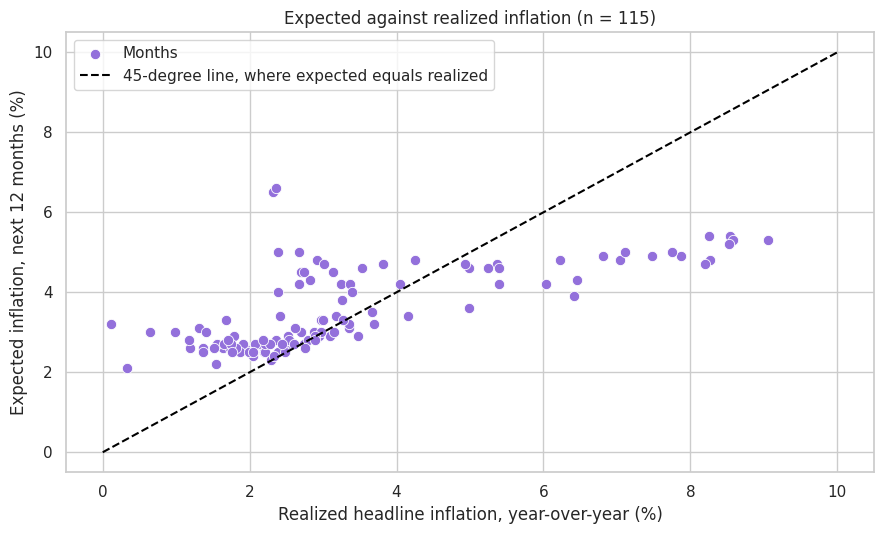

In [20]:
# Compare expected and realized inflation directly, with a 45-degree reference line
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=exp_df, x="headline_yoy_pct", y="expected_inflation_pct", s=55,
                color="mediumpurple", edgecolor="white", label="Months")
plt.plot([0, 10], [0, 10], color="black", linestyle="--", linewidth=1.5,
         label="45-degree line, where expected equals realized")
plt.xlabel("Realized headline inflation, year-over-year (%)")
plt.ylabel("Expected inflation, next 12 months (%)")
plt.title("Expected against realized inflation (n = 115)")
plt.legend()
plt.tight_layout()
plt.show()

**Predicted expected inflation = 2.35 + 0.35 × headline inflation**

A one percentage point increase in headline inflation is associated with **0.35 percentage points** higher expected inflation, with **R² = 0.492**. The intercept is the line's prediction at zero headline inflation, slightly outside our observed range. It is not a lower bound on expectations.

Expectations exceed recent headline inflation in **78 of 115 months**. This is not evidence that households overpredicted inflation: expectations cover the next twelve months, while headline inflation covers the previous twelve.

Expectations remain a descriptive comparison. Their correlation with monthly returns is weak (**−0.035**) in this sample.

### What our exploratory analysis changed

We retain our main research question, but the weak same-month correlations suggest that inflation alone explains little of the variation in monthly returns. The relationship using the previous month’s inflation has not yet been tested.

The plots also highlight the 2020 extremes and the close relationship between headline and core inflation. We will discuss these features when reporting the later models. Expectations remain a secondary descriptive comparison.

We did not collect additional data or change the sample based on these results.

## Questions for Reviewers

1. Should we add a clearly labeled sensitivity analysis for the 2020 extremes while retaining all months in the planned models?
2. Are slopes, R², and a discussion of limitations sufficient at this stage, or should the later analysis include a method for uncertainty that accounts for time dependence?
3. Is a previous-calendar-month inflation model sufficiently distinct from the same-month headline model for the two required analyses?
4. Is excluding and documenting the missing October 2025 CPI observation appropriate?
5. Should we keep the project focused on simple associations, or add a control variable such as an interest rate as a separate extension?

# Part 2: Preregistration of Analyses

### Scope of the proposed analyses

The two hypotheses and analysis plans are given in full below. Neither return regression is fitted in this notebook. EDA 1 and EDA 2 already reveal the slope direction and R² of the first, same-month model. The second analysis uses a one-calendar-month lag and has not been evaluated by those EDA results. We will report both models regardless of their results.

Statement 1 uses the **116 months from January 2017 through September 2026**, excluding October 2025 because CPI is missing. Statement 2 matches each month's return with inflation from the immediately preceding calendar month within the cleaned dataset, yielding **114 months**: January 2017 has no preceding month in the analysis dataset, and November 2025 has no October 2025 inflation value. We retain genuine extreme returns, do not fill missing months, and will identify any later changes to the plans.

### Preregistration Statement 1 — Headline inflation and monthly returns

**Hypothesis:** Higher year-over-year headline inflation is associated with lower same-month S&P 500 price returns.

Higher inflation may coincide with rising interest rates or business costs, which could put pressure on stock prices. Strong demand could work in the other direction, so a negative relationship is a hypothesis rather than an assumption.

**Proposed analysis:** Use simple linear regression with an intercept, implemented with `LinearRegression`, to fit

**Predicted monthly return = intercept + headline slope × same-month headline inflation**

The predictor is `headline_yoy_pct` and the outcome is `sp500_return_pct`. Report the sample size, intercept, slope, R², and a scatterplot with the fitted line. Interpret the slope as percentage points of monthly return per one percentage point of headline inflation.

We will describe whether the slope is negative and how much variation the model explains. Its sign alone does not establish statistical significance or causation. We will discuss the model assumptions before making uncertainty claims.

### Preregistration Statement 2 — Previous-month headline inflation and monthly returns

**Hypothesis:** Higher year-over-year headline inflation in the previous calendar month is associated with lower S&P 500 price returns in the current month.

Inflation could be related to stock returns with a delay, so we want to check whether the previous month's inflation is associated with current-month returns rather than only comparing values from the same month. This is still an association, not evidence of causation or a trading forecast: the previous month's CPI is usually released during the current month, not before it begins.

**Proposed analysis:** Use a simple linear regression with an intercept, implemented with `LinearRegression`, to fit

**Predicted monthly return = intercept + lagged headline slope × previous-month headline inflation**

The outcome is `sp500_return_pct`. The predictor is the value of `headline_yoy_pct` for the **previous calendar month**, matched using `month_index - 1` (not a row-wise shift, which would incorrectly bridge the missing October 2025 data). We will construct this lagged variable for Phase 3, before fitting the model. The final sample has **114 months**.

Report the sample size, intercept, slope, R², and a scatterplot with the fitted line. Interpret the slope as percentage points of current-month return per one percentage point of previous-month headline inflation. We will discuss the model's limitations and will not infer statistical significance or causation from the slope alone.

### Scope

Core inflation and expectations remain descriptive comparisons. Other than the two observations without an immediately preceding month of inflation in Statement 2, we will not drop months, add predictors, or adjust models to obtain a preferred result. Any mentor-requested extension will be labeled separately and reported alongside these models.

### Questions for Reviewers (Part 2)

1. Does the previous-month inflation model offer a sufficiently distinct second analysis from the same-month model, given the EDA correlations already shown?
2. Is matching inflation by the preceding calendar month appropriate, given the timing of CPI releases?
3. What treatment of regression uncertainty is appropriate for this course and these monthly observations?
4. If both models explain little return variation, what additional discussion would make the final report most useful?

## Sources and Acknowledgements

The sources below document the data, course materials, and assistance used in this project.

### Data sources

All data are public and were downloaded as `.csv` files. Direct links are also given in the Data Description section above.

- Federal Reserve Bank of St. Louis, FRED, series `SP500`, S&P 500 index level, produced by S&P Dow Jones Indices LLC. https://fred.stlouisfed.org/series/SP500
- U.S. Bureau of Labor Statistics, CPI for All Urban Consumers, All Items, not seasonally adjusted, series `CPIAUCNS`, via FRED. https://fred.stlouisfed.org/series/CPIAUCNS
- U.S. Bureau of Labor Statistics, CPI for All Urban Consumers, All Items Less Food and Energy, not seasonally adjusted, series `CPILFENS`, via FRED. https://fred.stlouisfed.org/series/CPILFENS
- University of Michigan Surveys of Consumers, inflation expectations, series `MICH`, via FRED. https://fred.stlouisfed.org/series/MICH

### Published work cited

- Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM*, 64(12), 86–92. https://arxiv.org/abs/1803.09010 — the format of our Data Description section follows this paper, as the Phase II rubric requires.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=d54e5c07-9be0-4c6a-9afb-6f108d6f3b05' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>